# ARGus · Random Forest vs XGBoost (k = 6)

**Lo que pidió la asesora:** probar XGBoost con k = 6 y compararlo contra el Random Forest
para ver si da mejores resultados.

**Cómo está armada la comparación para que sea válida:**

1. **Mismos datos exactos.** Los dos modelos se entrenan con el mismo corte por gen, el mismo
   submuestreo de negativos y los mismos 4096 k-meros. Lo único que cambia es el algoritmo.
2. **Mismo corte por gen.** Un gen y todos sus fragmentos van al mismo lado (train o test).
   Si se repartieran fragmentos al azar, pedazos del mismo gen quedarían en los dos lados y
   los resultados saldrían inflados.
3. **Los 2000 genes del 1k+1k quedan fuera del entrenamiento**, con un `assert` que lo verifica.
4. **Fragmentación corregida** en la evaluación del 1k+1k (el último bloque se corre hacia
   atrás en vez de rellenarse con ceros).
5. **Varias semillas de submuestreo.** Ésta es la parte importante: una sola corrida no permite
   decidir. Si XGBoost gana por 0.01 pero la variación entre semillas es de 0.02, ese 0.01 es
   ruido. El cuaderno mide la **diferencia emparejada** (mismo corte, misma semilla, los dos
   modelos) que es la forma correcta de comparar.

**Antes de correr:** `pip install xgboost` (o `conda install -c conda-forge xgboost`).

In [4]:
# ============ CELDA 1: configuración ============
import re, time, json, joblib, sys
from pathlib import Path
import numpy as np, pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
except ImportError:
    sys.exit("Falta XGBoost. Instálalo con:  pip install xgboost")

# --- carpeta data/interim (si la ruta no existe, la busca sola) ---
INTERIM_MANUAL = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim"
INTERIM = Path(INTERIM_MANUAL)
if not (INTERIM / "dataset_fragmentado_500.tsv").exists():
    hits = []
    for raiz in (Path("/mnt/c/Users"), Path.home()):
        if raiz.exists(): hits += list(raiz.rglob("dataset_fragmentado_500.tsv"))
    assert hits, "No encontré dataset_fragmentado_500.tsv: corrige INTERIM_MANUAL"
    INTERIM = hits[0].parent
print("INTERIM =", INTERIM)

DATASET_FRAG = INTERIM / "dataset_fragmentado_500.tsv"
SET_1K1K     = INTERIM / "muestra_genes_labels.tsv"
FASTA_1K1K   = INTERIM / "muestra_genes_completos.fasta"
SALIDA = INTERIM.parent / "models"; SALIDA.mkdir(parents=True, exist_ok=True)

# --- qué conjunto de positivos: None = 95 % (el que mejor salió) ---
POSITIVOS_FILTRO = None                    # o INTERIM / "positivo_id90_limpio.fasta"
ETIQUETA_CORRIDA = "id95"
PCT = "95"

K = 6                                      # indicación de la asesora
VENTANA = 500
SEED = 42
FRAC_TEST = 0.10
N_SEMILLAS = 5                             # corridas con distinto submuestreo (1 = solo una)

# --- hiperparámetros ---
RF_PARAMS  = dict(n_estimators=200, n_jobs=-1, random_state=SEED)
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.1, max_depth=6,
                  subsample=0.8, colsample_bytree=0.3,
                  tree_method="hist", eval_metric="logloss",
                  n_jobs=-1, random_state=SEED)

print(f"K = {K} | {4**K} características | positivos: {PCT} % | semillas: {N_SEMILLAS}")
print("sklearn", sklearn.__version__, "| xgboost", xgb.__version__)

INTERIM = /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim
K = 6 | 4096 características | positivos: 95 % | semillas: 5
sklearn 1.9.1 | xgboost 3.2.0


In [5]:
# ============ CELDA 2: cargar fragmentos, asignar gen y excluir los 2000 genes ============
frag = pd.read_csv(DATASET_FRAG, sep="\t")
col_id, col_seq, col_lab = "id", "lectura", "etiqueta"
assert {col_id, col_seq, col_lab} <= set(frag.columns), f"columnas: {list(frag.columns)}"
frag[col_lab] = frag[col_lab].astype(int)

# el gen es el id sin el sufijo "__fragN"
frag["gen"] = frag[col_id].str.replace(r"__frag\d+$", "", regex=True)
print(f"{len(frag):,} fragmentos de {frag['gen'].nunique():,} genes")

# --- excluir los 2000 genes del 1k+1k ---
lab1k = pd.read_csv(SET_1K1K, sep="\t")
ids_1k = set(lab1k.iloc[:, 0].astype(str))
genes_frag = set(frag["gen"])
excluir = ids_1k & genes_frag
faltan = ids_1k - excluir
if faltan:                                  # respaldo: probar sin el prefijo del genoma
    variantes = {}
    for g in genes_frag: variantes.setdefault(g.split("|", 1)[-1], g)
    for f in list(faltan):
        if f in variantes: excluir.add(variantes[f]); faltan.discard(f)
assert not faltan, f"No encontré genes del 1k+1k: {list(faltan)[:5]}"
print(f"genes del 1k+1k excluidos: {len(excluir)} de {len(ids_1k)}")

pool = frag[~frag["gen"].isin(excluir)].reset_index(drop=True)

# --- filtro opcional de positivos (90 % / 85 %) ---
if POSITIVOS_FILTRO is not None:
    hdrs = [l[1:].strip() for l in open(POSITIVOS_FILTRO) if l.startswith(">")]
    ids_ok = set(hdrs) | {h.split()[0] for h in hdrs}
    quitar = (pool[col_lab] == 1) & (~pool["gen"].isin(ids_ok))
    print("fragmentos positivos fuera del set filtrado (se quitan):", quitar.sum())
    pool = pool[~quitar].reset_index(drop=True)

print(pool[col_lab].value_counts().rename({0: "neg (frag)", 1: "pos (frag)"}))

72,874 fragmentos de 30,741 genes
genes del 1k+1k excluidos: 2000 de 2000
etiqueta
neg (frag)    60978
pos (frag)     7229
Name: count, dtype: int64


In [6]:
# ============ CELDA 3: k-meros y fragmentación (la corregida) ============
LUT = np.full(256, 4, dtype=np.int8)
for _i, _b in enumerate(b"ACGT"): LUT[_b] = _i
POT = (4 ** np.arange(K - 1, -1, -1)).astype(np.int64)

def vector_kmer(seq):
    # Frecuencia relativa de los 4**K k-meros; las ventanas que contienen '0'
    # (relleno) o cualquier base que no sea ACGT se ignoran.
    a = LUT[np.frombuffer(seq.upper().encode("ascii", "replace"), dtype=np.uint8)]
    out = np.zeros(4 ** K, dtype=np.float32)
    if len(a) - K + 1 <= 0: return out
    win = np.lib.stride_tricks.sliding_window_view(a, K)
    ok = (win < 4).all(axis=1)
    if not ok.any(): return out
    idx = (win[ok].astype(np.int64) * POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K).astype(np.float32)
    return out / out.sum()

def matriz(seqs):
    X = np.empty((len(seqs), 4 ** K), dtype=np.float32)
    for i, s in enumerate(seqs): X[i] = vector_kmer(s)
    return X

def fragmentar(seq, ventana=VENTANA):
    # CORREGIDA: el último bloque se corre hacia atrás en vez de rellenarse con ceros.
    # Se solapa con el anterior, pero no pierde ninguna base y el vector sale completo.
    seq = seq.upper(); L = len(seq)
    if L < ventana: return [seq + "0" * (ventana - L)]   # genes cortos: inevitable
    n = L // ventana
    fr = [seq[i*ventana:(i+1)*ventana] for i in range(n)]
    if L % ventana: fr.append(seq[-ventana:])
    return fr

assert abs(vector_kmer("ACGT" * 125).sum() - 1.0) < 1e-5
assert len(fragmentar("A" * 504)) == 2 and all(len(f) == 500 for f in fragmentar("A" * 504))
assert "0" not in "".join(fragmentar("A" * 1503))        # ya no hay relleno
print("k-meros y fragmentación OK")

k-meros y fragmentación OK


In [7]:
# ============ CELDA 4: corte por gen (fijo) y fragmentos del 1k+1k ============
y_all = pool[col_lab].values
g_all = pool["gen"].values
seqs_all = pool[col_seq].astype(str).values

# El corte train/test es el MISMO para todas las semillas y para los dos modelos.
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / FRAC_TEST)), shuffle=True, random_state=SEED)
tr_full, te = next(sgkf.split(np.zeros(len(y_all)), y_all, g_all))
assert not set(g_all[tr_full]) & set(g_all[te]), "FUGA: un gen aparece en train y test"
print(f"train: {len(tr_full):,} fragmentos ({len(set(g_all[tr_full])):,} genes) | "
      f"pos={int(y_all[tr_full].sum()):,} neg={int((y_all[tr_full]==0).sum()):,}")
print(f"test : {len(te):,} fragmentos ({len(set(g_all[te])):,} genes) | "
      f"pos={int(y_all[te].sum()):,} neg={int((y_all[te]==0).sum()):,}  (proporción natural)")

def submuestrear(idx, semilla):
    # Todos los positivos + igual número de negativos al azar (Random Undersampling).
    rng = np.random.default_rng(semilla)
    p = idx[y_all[idx] == 1]; n = idx[y_all[idx] == 0]
    sel = np.concatenate([p, rng.choice(n, size=min(len(p), len(n)), replace=False)])
    rng.shuffle(sel); return sel

# --- features del test: se calculan UNA vez (el test no cambia) ---
t0 = time.time()
X_te = matriz(seqs_all[te]); y_te = y_all[te]; g_te = g_all[te]
print(f"X_test: {X_te.shape}  {X_te.nbytes/1e6:.0f} MB  ({time.time()-t0:.0f}s)")

# --- fragmentos de los 2000 genes, con la fragmentación CORREGIDA ---
def leer_fasta(path):
    d, cur = {}, None
    for l in open(path, encoding="utf-8", errors="replace"):
        l = l.strip()
        if l.startswith(">"): cur = l[1:].split()[0]; d[cur] = []
        elif cur: d[cur].append(l)
    return {k: "".join(v) for k, v in d.items()}

fa = leer_fasta(FASTA_1K1K)
y_1k = dict(zip(lab1k.iloc[:, 0].astype(str), lab1k.iloc[:, 1].astype(int)))
ids_1k_ok = [i for i in fa if i in y_1k]
seqs_1k, gen_1k = [], []
for gid in ids_1k_ok:
    fr = fragmentar(fa[gid]); seqs_1k += fr; gen_1k += [gid] * len(fr)
gen_1k = np.array(gen_1k)
t0 = time.time()
X_1k = matriz(seqs_1k)
print(f"1k+1k: {len(ids_1k_ok)} genes -> {len(seqs_1k):,} fragmentos | "
      f"X_1k {X_1k.nbytes/1e6:.0f} MB ({time.time()-t0:.0f}s)")

train: 61,386 fragmentos (25,867 genes) | pos=6,506 neg=54,880
test : 6,821 fragmentos (2,874 genes) | pos=723 neg=6,098  (proporción natural)
X_test: (6821, 4096)  112 MB  (1s)
1k+1k: 2000 genes -> 4,667 fragmentos | X_1k 76 MB (0s)


In [8]:
# ============ CELDA 5: funciones de evaluación ============
UMBRAL = 0.5

def metricas(y, pred, p=None):
    d = dict(recall=recall_score(y, pred, zero_division=0),
             precision=precision_score(y, pred, zero_division=0),
             f1=f1_score(y, pred, zero_division=0))
    if p is not None and len(np.unique(y)) == 2: d["auc"] = roc_auc_score(y, p)
    return d

def por_gen(genes, y, p):
    # Regla de ARGus: un gen es ARG si ALGÚN fragmento alcanza el umbral.
    d = pd.DataFrame({"gen": genes, "y": y, "p": p}).groupby("gen").agg(
        y=("y", "max"), p=("p", "max"))
    return metricas(d.y.values, (d.p.values >= UMBRAL).astype(int), d.p.values), d

def evaluar(modelo, nombre):
    # Test interno (fragmento y gen) + 1k+1k (gen).
    p_te = modelo.predict_proba(X_te)[:, 1]
    m_frag = metricas(y_te, (p_te >= UMBRAL).astype(int), p_te)
    m_gen, _ = por_gen(g_te, y_te, p_te)

    p1 = modelo.predict_proba(X_1k)[:, 1]
    r = pd.DataFrame({"gen": gen_1k, "p": p1}).groupby("gen")["p"].max().reset_index()
    r["y"] = r["gen"].map(y_1k); r["pred"] = (r["p"] >= UMBRAL).astype(int)
    m_1k = metricas(r.y.values, r.pred.values, r.p.values)
    cm = confusion_matrix(r.y, r.pred)
    return dict(modelo=nombre, test_frag=m_frag, test_gen=m_gen, hold_1k=m_1k, cm=cm, r1k=r)

def fmt(m):
    return "  ".join(f"{k}={v:.3f}" for k, v in m.items())
print("listo")

listo


In [9]:
# ============ CELDA 6: entrenar los dos con los MISMOS datos (semilla principal) ============
tr_bal = submuestrear(tr_full, SEED)
print(f"train balanceado: {len(tr_bal):,} fragmentos  "
      f"pos={int(y_all[tr_bal].sum()):,}  neg={int((y_all[tr_bal]==0).sum()):,}")

t0 = time.time()
X_tr = matriz(seqs_all[tr_bal]); y_tr = y_all[tr_bal]
print(f"X_train: {X_tr.shape}  {X_tr.nbytes/1e6:.0f} MB  ({time.time()-t0:.0f}s)")

t0 = time.time(); rf = RandomForestClassifier(**RF_PARAMS).fit(X_tr, y_tr)
print(f"Random Forest entrenado en {time.time()-t0:.0f}s")

t0 = time.time(); xg = XGBClassifier(**XGB_PARAMS).fit(X_tr, y_tr)
print(f"XGBoost entrenado en {time.time()-t0:.0f}s")

train balanceado: 13,012 fragmentos  pos=6,506  neg=6,506
X_train: (13012, 4096)  213 MB  (1s)
Random Forest entrenado en 12s
XGBoost entrenado en 72s


In [10]:
# ============ CELDA 7: resultados de la semilla principal ============
res_rf = evaluar(rf, "Random Forest")
res_xg = evaluar(xg, "XGBoost")

for r in (res_rf, res_xg):
    print(f"\n===== {r['modelo']} =====")
    print("  TEST fragmento (natural):", fmt(r["test_frag"]))
    print("  TEST gen (algún frag)   :", fmt(r["test_gen"]))
    print("  1k+1k gen               :", fmt(r["hold_1k"]))
    cm = r["cm"]
    print(f"    matriz 1k+1k:   NO ARG pred   ARG pred")
    print(f"      real NO ARG      {cm[0,0]:>6}      {cm[0,1]:>6}   <- falsos positivos")
    print(f"      real ARG         {cm[1,0]:>6}      {cm[1,1]:>6}")
    print(f"    marcados como resistentes: {cm[0,1]+cm[1,1]}")

d_f1 = res_xg["hold_1k"]["f1"] - res_rf["hold_1k"]["f1"]
print(f"\nDiferencia en F1 (1k+1k), XGBoost - RF: {d_f1:+.3f}")
print("Todavía NO decidas con esto: falta la celda 8 (varias semillas).")


===== Random Forest =====
  TEST fragmento (natural): recall=0.748  precision=0.369  f1=0.495  auc=0.873
  TEST gen (algún frag)   : recall=0.867  precision=0.284  f1=0.428  auc=0.878
  1k+1k gen               : recall=0.861  precision=0.784  f1=0.821  auc=0.902
    matriz 1k+1k:   NO ARG pred   ARG pred
      real NO ARG         763         237   <- falsos positivos
      real ARG            139         861
    marcados como resistentes: 1098

===== XGBoost =====
  TEST fragmento (natural): recall=0.781  precision=0.319  f1=0.453  auc=0.882
  TEST gen (algún frag)   : recall=0.913  precision=0.239  f1=0.379  auc=0.901
  1k+1k gen               : recall=0.908  precision=0.754  f1=0.824  auc=0.909
    matriz 1k+1k:   NO ARG pred   ARG pred
      real NO ARG         703         297   <- falsos positivos
      real ARG             92         908
    marcados como resistentes: 1205

Diferencia en F1 (1k+1k), XGBoost - RF: +0.003
Todavía NO decidas con esto: falta la celda 8 (varias semill

In [11]:
# ============ CELDA 8 (CORREGIDA): ¿la diferencia es real o es ruido del submuestreo? ============
# Mantiene el mismo protocolo de siempre: corte por gen FIJO (StratifiedGroupKFold, misma
# semilla), Random Undersampling solo de negativos dentro del train, fragmentación corregida
# en el 1k+1k, y la regla de gen "algún fragmento >= umbral".
#
# Lo único que cambia entre semillas es QUÉ negativos salieron en el sorteo. El corte
# train/test NO cambia, a propósito: así los dos modelos ven datos idénticos en cada semilla
# y la comparación es emparejada.
#
# CORRECCIÓN respecto a la versión anterior: el veredicto comparaba la media contra
# 2 x desviación estándar. Eso está mal. La desviación mide cuánto varían las diferencias
# individuales; para juzgar si la MEDIA es distinta de cero se usa el error estándar de la
# media (sem = desviación / raíz de n). Con n = 5 el umbral baja de 2*sd a 2*sem, o sea
# a la mitad aproximadamente, y la conclusión puede cambiar.

import numpy as np, pandas as pd
from math import sqrt

# --- si la celda ya se corrió antes, reutiliza los resultados y NO reentrena ---
ya_esta = ("est" in globals() and isinstance(est, pd.DataFrame)
           and {"semilla", "modelo", "f1", "auc"} <= set(est.columns)
           and len(est) == 2 * N_SEMILLAS)

if ya_esta:
    print(f"Reutilizando los {len(est)} resultados ya calculados (no reentrena).")
else:
    filas = []
    for i in range(N_SEMILLAS):
        s = SEED + i
        sel = submuestrear(tr_full, s)                      # mismo submuestreo de siempre
        Xs = matriz(seqs_all[sel]); ys = y_all[sel]
        for nombre, modelo in [("RF",  RandomForestClassifier(**{**RF_PARAMS,  "random_state": s})),
                               ("XGB", XGBClassifier(**{**XGB_PARAMS, "random_state": s}))]:
            modelo.fit(Xs, ys)
            r = evaluar(modelo, nombre)                     # 1k+1k con fragmentación corregida
            filas.append(dict(semilla=s, modelo=nombre,
                              **{k: round(v, 4) for k, v in r["hold_1k"].items()},
                              fp=int(r["cm"][0, 1]), fn=int(r["cm"][1, 0])))
        del Xs
        print(f"  semilla {s} lista ({i+1}/{N_SEMILLAS})")
    est = pd.DataFrame(filas)

print("\n--- por semilla (1k+1k, nivel gen) ---")
print(est.to_string(index=False))

print("\n--- media ± desviación estándar ---")
print(est.groupby("modelo")[["recall", "precision", "f1", "auc", "fp"]]
         .agg(["mean", "std"]).round(4).to_string())

# ---------------------------------------------------------------------------
# COMPARACIÓN EMPAREJADA: misma semilla, mismos negativos, los dos modelos
# ---------------------------------------------------------------------------
# t de Student para 0.05 a dos colas (para no depender de scipy)
T_CRIT = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365,
          8: 2.306, 9: 2.262, 10: 2.228, 11: 2.201, 12: 2.179, 13: 2.160, 14: 2.145,
          15: 2.131, 16: 2.120, 17: 2.110, 18: 2.101, 19: 2.093, 20: 2.086,
          21: 2.080, 22: 2.074, 23: 2.069, 24: 2.064, 25: 2.060, 30: 2.042}

def t_critico(gl):
    if gl in T_CRIT: return T_CRIT[gl]
    return 2.042 if gl > 30 else T_CRIT[min(T_CRIT, key=lambda k: abs(k - gl))]

def comparar(metrica, mayor_es_mejor=True):
    piv = est.pivot(index="semilla", columns="modelo", values=metrica)
    d = (piv["XGB"] - piv["RF"]).values
    n = len(d); media = d.mean()
    if n < 2:
        return dict(metrica=metrica, media=media, sd=np.nan, sem=np.nan,
                    t=np.nan, gl=0, signif=False, mismo_signo=True, n=n,
                    dif=d, mejor_mas=mayor_es_mejor)
    sd = d.std(ddof=1); sem = sd / sqrt(n)
    t = media / sem if sem > 0 else (np.inf if media != 0 else 0.0)
    gl = n - 1
    return dict(metrica=metrica, media=media, sd=sd, sem=sem, t=t, gl=gl,
                signif=abs(t) > t_critico(gl), mismo_signo=bool((d > 0).all() or (d < 0).all()),
                n=n, dif=d, mejor_mas=mayor_es_mejor)

METRICAS = [("f1", True), ("auc", True), ("recall", True), ("precision", True), ("fp", False)]
comps = [comparar(m, b) for m, b in METRICAS]

print("\n" + "=" * 86)
print("DIFERENCIAS EMPAREJADAS (XGBoost - Random Forest)")
print(f"  n = {comps[0]['n']} semillas | {comps[0]['gl']} grados de libertad | "
      f"t crítico (0.05, dos colas) = {t_critico(comps[0]['gl']):.3f}")
print("-" * 86)
print(f"  {'métrica':<11} {'media':>10} {'sd':>9} {'sem':>9} {'t':>8}  {'signif.':<9} signos")
for c in comps:
    if np.isnan(c["sem"]):
        print(f"  {c['metrica']:<11} {c['media']:>+10.4f}   (hace falta N_SEMILLAS >= 2)")
        continue
    sig = "SÍ" if c["signif"] else "no"
    signos = "todas +" if (c["dif"] > 0).all() else ("todas -" if (c["dif"] < 0).all() else "mezcladas")
    print(f"  {c['metrica']:<11} {c['media']:>+10.4f} {c['sd']:>9.4f} {c['sem']:>9.4f} "
          f"{c['t']:>+8.2f}  {sig:<9} {signos}")

# --- prueba de signos: no supone normalidad, útil con pocas semillas ---
cf1 = next(c for c in comps if c["metrica"] == "f1")
n = cf1["n"]; pos = int((cf1["dif"] > 0).sum())
p_signos = 2 * 0.5 ** n if pos in (0, n) else None
print("-" * 86)
print(f"  Prueba de signos sobre F1: {pos} de {n} semillas favorecen a XGBoost", end="")
print(f" | p = {p_signos:.4f}" if p_signos is not None else " | signos mezclados")

# ---------------------------------------------------------------------------
# VEREDICTO
# ---------------------------------------------------------------------------
print("\n" + "=" * 86)
print("VEREDICTO")
f1, auc = cf1, next(c for c in comps if c["metrica"] == "auc")
rec = next(c for c in comps if c["metrica"] == "recall")
pre = next(c for c in comps if c["metrica"] == "precision")
fp  = next(c for c in comps if c["metrica"] == "fp")

if np.isnan(f1["sem"]):
    print("  Con una sola semilla no se puede decidir. Pon N_SEMILLAS >= 3 y vuelve a correr.")
else:
    gana = "XGBoost" if f1["media"] > 0 else "Random Forest"
    if f1["signif"]:
        print(f"  F1: la diferencia es CONSISTENTE y favorece a {gana} "
              f"({f1['media']:+.4f}, t = {f1['t']:+.2f}).")
    else:
        print(f"  F1: la diferencia ({f1['media']:+.4f}, t = {f1['t']:+.2f}) NO supera el ruido "
              f"del submuestreo.\n      No se puede afirmar que un modelo sea mejor en F1.")

    if auc["signif"]:
        quien = "XGBoost" if auc["media"] > 0 else "Random Forest"
        print(f"  AUC: {quien} ordena mejor los genes ({auc['media']:+.4f}, t = {auc['t']:+.2f}).")
        print("       El AUC no depende del umbral, así que ésta es la comparación más limpia")
        print("       entre los dos algoritmos.")
    else:
        print(f"  AUC: sin diferencia clara ({auc['media']:+.4f}).")

    # el intercambio recall/precisión es lo que suele esconder el F1
    if rec["signif"] and pre["signif"] and np.sign(rec["media"]) != np.sign(pre["media"]):
        suben = "XGBoost" if rec["media"] > 0 else "Random Forest"
        print(f"\n  OJO: no es una mejora pareja, es un INTERCAMBIO. {suben} gana recall "
              f"({rec['media']:+.3f})")
        print(f"       y pierde precisión ({pre['media']:+.3f}); los falsos positivos cambian "
              f"en {fp['media']:+.0f}.")
        print("       El F1 casi no se mueve porque las dos cosas se cancelan. Cuál conviene")
        print("       depende de la prevalencia real de ARG, y el test interno (proporción")
        print("       natural) se parece más a un MAG que el 1k+1k, que está balanceado 50/50.")
        print("\n       Siguiente paso: ajustar el umbral de cada modelo con el train o el test")
        print("       interno (NUNCA con el 1k+1k) y recién entonces comparar.")

print("\n  Alcance de esta medición: captura el ruido del sorteo de negativos, que es lo que")
print("  varía entre semillas. No captura el ruido de qué genes cayeron en el test, porque")
print("  el corte train/test se mantiene fijo a propósito para que la comparación sea")
print("  emparejada. Medir eso requeriría validación cruzada repetida.")

est.to_csv(SALIDA / f"estabilidad_rf_vs_xgb_{ETIQUETA_CORRIDA}.csv", index=False)
pd.DataFrame([{k: v for k, v in c.items() if k not in ("dif", "mejor_mas")} for c in comps]) \
  .to_csv(SALIDA / f"comparacion_emparejada_{ETIQUETA_CORRIDA}.csv", index=False)
print(f"\nGuardado: estabilidad_rf_vs_xgb_{ETIQUETA_CORRIDA}.csv y "
      f"comparacion_emparejada_{ETIQUETA_CORRIDA}.csv")

  semilla 42 lista (1/5)
  semilla 43 lista (2/5)
  semilla 44 lista (3/5)
  semilla 45 lista (4/5)
  semilla 46 lista (5/5)

--- por semilla (1k+1k, nivel gen) ---
 semilla modelo  recall  precision     f1    auc  fp  fn
      42     RF   0.861     0.7842 0.8208 0.9024 237 139
      42    XGB   0.908     0.7535 0.8236 0.9092 297  92
      43     RF   0.862     0.7822 0.8202 0.9006 240 138
      43    XGB   0.913     0.7564 0.8274 0.9122 294  87
      44     RF   0.871     0.7889 0.8279 0.9046 233 129
      44    XGB   0.908     0.7611 0.8281 0.9180 285  92
      45     RF   0.859     0.7910 0.8236 0.8997 227 141
      45    XGB   0.911     0.7573 0.8271 0.9122 292  89
      46     RF   0.874     0.7818 0.8253 0.9041 244 126
      46    XGB   0.909     0.7697 0.8336 0.9183 272  91

--- media ± desviación estándar ---
        recall         precision              f1             auc             fp        
          mean     std      mean     std    mean     std    mean     std   mean    

                     recall  precision     f1    auc   FP
Random Forest (k=6)   0.861      0.784  0.821  0.902  237
XGBoost (k=6)         0.908      0.754  0.824  0.909  297


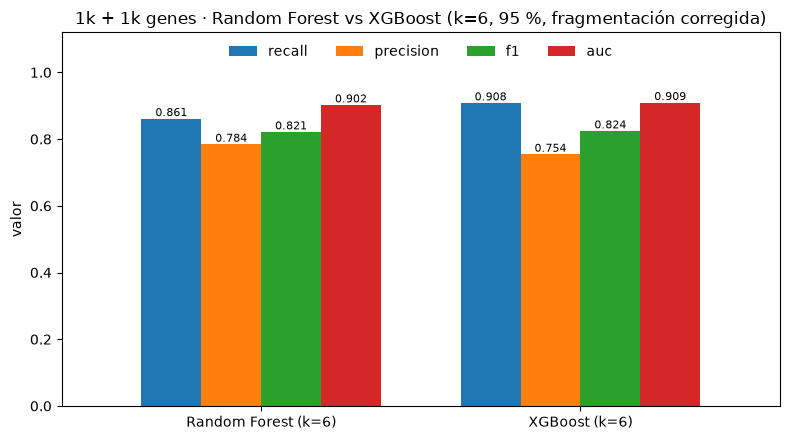

In [12]:
# ============ CELDA 9: tabla y gráfica ============
import matplotlib.pyplot as plt

tabla = pd.DataFrame({
    "Random Forest (k=6)": {k: round(v, 3) for k, v in res_rf["hold_1k"].items()},
    "XGBoost (k=6)":       {k: round(v, 3) for k, v in res_xg["hold_1k"].items()},
}).T[["recall", "precision", "f1", "auc"]]
tabla["FP"] = [int(res_rf["cm"][0, 1]), int(res_xg["cm"][0, 1])]
print(tabla.to_string())
tabla.to_csv(SALIDA / f"comparacion_rf_vs_xgb_{ETIQUETA_CORRIDA}.csv")

ax = tabla[["recall", "precision", "f1", "auc"]].plot.bar(figsize=(8, 4.5), rot=0, width=0.75)
ax.set_ylim(0, 1.12); ax.set_ylabel("valor")
ax.set_title(f"1k + 1k genes · Random Forest vs XGBoost (k=6, {PCT} %, fragmentación corregida)")
ax.legend(loc="upper center", ncol=4, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / f"comparacion_rf_vs_xgb_{ETIQUETA_CORRIDA}.png", dpi=200)
plt.show()

In [13]:
# ============ CELDA 10: guardar el modelo XGBoost (mismo formato que el RF) ============
# La GUI carga este formato sin cambios: deduce K de n_features_in_ y usa predict_proba.
ruta = SALIDA / f"argus_xgb_k{K}_{ETIQUETA_CORRIDA}.joblib"
joblib.dump({"modelo": xg, "K": K, "ventana": VENTANA,
             "relleno": "ninguno (último bloque corrido hacia atrás)",
             "regla_gen": "any", "umbral": UMBRAL, "semilla": SEED,
             "algoritmo": "XGBClassifier", "xgboost": xgb.__version__,
             "hiperparametros": XGB_PARAMS,
             "metricas_test_fragmento": res_xg["test_frag"],
             "metricas_test_gen": res_xg["test_gen"],
             "metricas_1k1k_gen": res_xg["hold_1k"]},
            ruta, compress=3)
print("guardado:", ruta, f"{ruta.stat().st_size/1e6:.0f} MB")

chk = joblib.load(ruta)["modelo"]
assert np.array_equal(chk.predict(X_1k), xg.predict(X_1k)), "el modelo recargado difiere"
print("recarga verificada: mismas predicciones sobre el 1k+1k")

# predicciones por gen, para el análisis de falsos positivos
res_xg["r1k"].to_csv(SALIDA / f"r1k_xgb_{ETIQUETA_CORRIDA}.csv", index=False)
res_rf["r1k"].to_csv(SALIDA / f"r1k_rf_{ETIQUETA_CORRIDA}.csv", index=False)
print("guardadas las predicciones por gen de los dos modelos")

guardado: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/models/argus_xgb_k6_id95.joblib 0 MB
recarga verificada: mismas predicciones sobre el 1k+1k
guardadas las predicciones por gen de los dos modelos


  pliegue 1/5 listo (75s)
  pliegue 2/5 listo (146s)
  pliegue 3/5 listo (219s)
  pliegue 4/5 listo (293s)
  pliegue 5/5 listo (368s)

Genes en el train: 2,905 positivos / 22,962 negativos (1 por cada 7.9)

modelo  umbral 1:1  F1 int.    umbral dataset  F1 int.    F1 int. @0.50
RF            0.52    0.820              0.59    0.554            0.815
XGB           0.61    0.820              0.80    0.599            0.804

RESULTADO (nivel gen, regla: algún fragmento >= umbral)

--- TEST interno (natural) ---
modelo                 umbral  recall  precision    f1  fp  fn
    RF     0.50 (por defecto)   0.867      0.284 0.428 705  43
    RF     0.52 (elegido 1:1)   0.827      0.331 0.473 539  56
    RF 0.59 (elegido dataset)   0.672      0.478 0.559 237 106
   XGB     0.50 (por defecto)   0.913      0.239 0.379 940  28
   XGB     0.61 (elegido 1:1)   0.858      0.312 0.458 610  46
   XGB 0.80 (elegido dataset)   0.622      0.618 0.620 124 122

--- 1k+1k (50/50) ---
modelo                 u

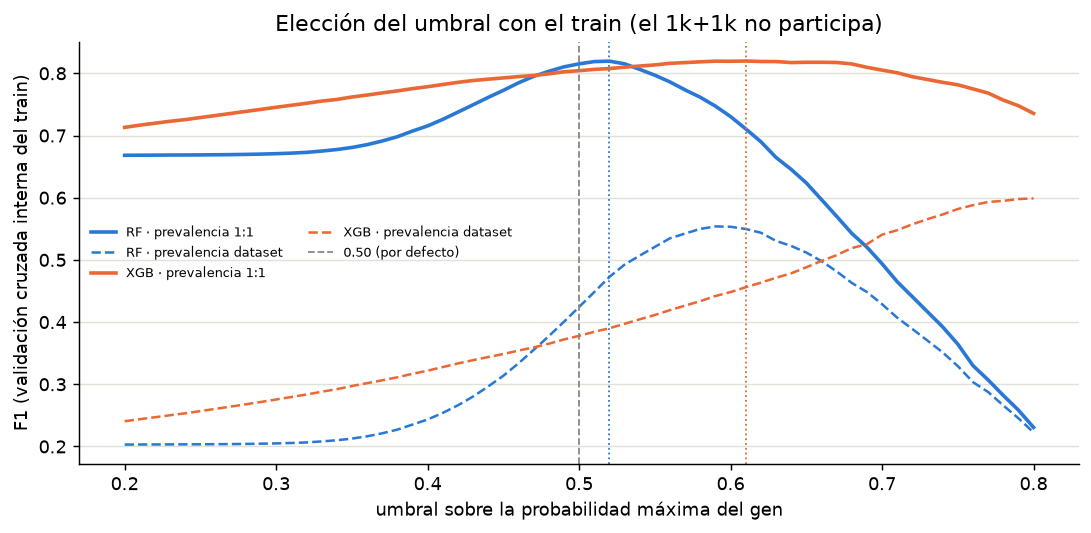


Umbrales elegidos: {'RF': {'1a1': 0.52, 'dataset': 0.59}, 'XGB': {'1a1': 0.61, 'dataset': 0.8}}
Guardado: umbral_rf_vs_xgb_id95.csv y curva_umbral_id95.csv


In [14]:
# ============ CELDA 11: ajuste del umbral con validación interna del TRAIN ============
# Por qué hace falta: el submuestreo entrena los modelos como si hubiera 50 % de positivos,
# así que el corte en 0.5 no tiene por qué ser el mejor. Y XGBoost y Random Forest calibran
# distinto, así que cada uno necesita SU propio umbral. Comparar los dos en 0.5 compara
# puntos de operación arbitrarios, no la calidad de los modelos.
#
# REGLA METODOLÓGICA: el umbral se elige SOLO con el train, por validación cruzada interna
# separada por gen. Después se aplica UNA sola vez al test interno y al 1k+1k. Si se eligiera
# mirando el 1k+1k, ese conjunto dejaría de ser una evaluación imparcial.
#
# Protocolo idéntico al resto del cuaderno: corte por gen, Random Undersampling solo de
# negativos y solo dentro de cada pliegue de entrenamiento, regla de gen "algún fragmento
# >= umbral", fragmentación corregida en el 1k+1k.

import numpy as np, pandas as pd, time
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, recall_score, precision_score

N_FOLDS_UMBRAL = 5
UMBRALES = np.round(np.arange(0.20, 0.8001, 0.01), 2)

# ---------------------------------------------------------------------------
# 1) Predicciones fuera de muestra (OOF) dentro del train, para los dos modelos
# ---------------------------------------------------------------------------
# En cada pliegue: se entrena con los negativos SUBMUESTREADOS de los otros pliegues,
# y se predice sobre TODOS los fragmentos del pliegue retenido (sin submuestrear), para
# que el máximo por gen tenga sentido.
sgkf_in = StratifiedGroupKFold(n_splits=N_FOLDS_UMBRAL, shuffle=True, random_state=SEED + 7)
oof = {"RF": np.zeros(len(tr_full)), "XGB": np.zeros(len(tr_full))}

t0 = time.time()
for k, (a, b) in enumerate(sgkf_in.split(np.zeros(len(tr_full)), y_all[tr_full], g_all[tr_full]), 1):
    ia, ib = tr_full[a], tr_full[b]
    assert not set(g_all[ia]) & set(g_all[ib]), "FUGA dentro de la CV interna"
    sel = submuestrear(ia, SEED)                       # mismo submuestreo de siempre
    Xa = matriz(seqs_all[sel]); ya = y_all[sel]
    Xb = matriz(seqs_all[ib])                          # TODOS los fragmentos del pliegue
    for nombre, modelo in [("RF",  RandomForestClassifier(**RF_PARAMS)),
                           ("XGB", XGBClassifier(**XGB_PARAMS))]:
        modelo.fit(Xa, ya)
        oof[nombre][b] = modelo.predict_proba(Xb)[:, 1]
    del Xa, Xb
    print(f"  pliegue {k}/{N_FOLDS_UMBRAL} listo ({time.time()-t0:.0f}s)")

# ---------------------------------------------------------------------------
# 2) A nivel gen dentro del train: la regla desplegada es "algún fragmento"
# ---------------------------------------------------------------------------
gen_tr = g_all[tr_full]; y_tr_frag = y_all[tr_full]
genes_oof = {}
for nombre in ("RF", "XGB"):
    d = pd.DataFrame({"gen": gen_tr, "y": y_tr_frag, "p": oof[nombre]})
    genes_oof[nombre] = d.groupby("gen").agg(y=("y", "max"), p=("p", "max"))

g0 = genes_oof["RF"]
n_pos, n_neg = int((g0.y == 1).sum()), int((g0.y == 0).sum())
print(f"\nGenes en el train: {n_pos:,} positivos / {n_neg:,} negativos "
      f"(1 por cada {n_neg/max(1,n_pos):.1f})")

# Dos escenarios de prevalencia:
#  - 1:1  -> comparable con el 1k+1k, que está balanceado 50/50
#  - dataset -> la proporción que trae el propio conjunto de entrenamiento
# OJO: un MAG real es MUCHO más desbalanceado que el dataset (1 % o menos de ARG),
# así que ninguno de los dos es el escenario de despliegue; para eso está la tabla
# de prevalencias del documento de hallazgos.
peso_1a1 = {nombre: np.where(g.y == 1, 1.0, n_pos / max(1, n_neg))
            for nombre, g in genes_oof.items()}

# ---------------------------------------------------------------------------
# 3) Barrido del umbral, SOLO con los datos del train
# ---------------------------------------------------------------------------
def curva(g, pesos):
    return np.array([f1_score(g.y.values, (g.p.values >= t).astype(int),
                              sample_weight=pesos, zero_division=0) for t in UMBRALES])

elegidos, curvas = {}, {}
print(f"\n{'modelo':<6} {'umbral 1:1':>11} {'F1 int.':>8}   {'umbral dataset':>15} {'F1 int.':>8}   "
      f"{'F1 int. @0.50':>14}")
i50 = int(np.where(UMBRALES == 0.50)[0][0])
for nombre, g in genes_oof.items():
    f_bal, f_nat = curva(g, peso_1a1[nombre]), curva(g, None)
    t_bal = float(UMBRALES[f_bal.argmax()]); t_nat = float(UMBRALES[f_nat.argmax()])
    elegidos[nombre] = {"1a1": t_bal, "dataset": t_nat}
    curvas[nombre] = {"1a1": f_bal, "dataset": f_nat}
    print(f"{nombre:<6} {t_bal:>11.2f} {f_bal.max():>8.3f}   {t_nat:>15.2f} {f_nat.max():>8.3f}   "
          f"{f_bal[i50]:>14.3f}")

# ---------------------------------------------------------------------------
# 4) Aplicar los umbrales UNA vez, con los modelos ya entrenados de la celda 6
# ---------------------------------------------------------------------------
MODELOS = {"RF": rf, "XGB": xg}

# probabilidades por gen (se calculan una sola vez por modelo)
probs_gen = {}
for nombre, m in MODELOS.items():
    p_te = m.predict_proba(X_te)[:, 1]
    dte = pd.DataFrame({"gen": g_te, "y": y_te, "p": p_te}).groupby("gen").agg(
        y=("y", "max"), p=("p", "max"))
    p1 = m.predict_proba(X_1k)[:, 1]
    d1k = pd.DataFrame({"gen": gen_1k, "p": p1}).groupby("gen")["p"].max().reset_index()
    d1k["y"] = d1k["gen"].map(y_1k)
    probs_gen[nombre] = {"test": dte, "hold": d1k}

def met(y, p, t):
    pred = (np.asarray(p) >= t).astype(int)
    return dict(recall=recall_score(y, pred, zero_division=0),
                precision=precision_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                fp=int(((pred == 1) & (np.asarray(y) == 0)).sum()),
                fn=int(((pred == 0) & (np.asarray(y) == 1)).sum()))

filas = []
for nombre in ("RF", "XGB"):
    for etiqueta, t in [("0.50 (por defecto)", 0.50),
                        (f"{elegidos[nombre]['1a1']:.2f} (elegido 1:1)", elegidos[nombre]["1a1"]),
                        (f"{elegidos[nombre]['dataset']:.2f} (elegido dataset)", elegidos[nombre]["dataset"])]:
        dte, d1k = probs_gen[nombre]["test"], probs_gen[nombre]["hold"]
        filas.append(dict(modelo=nombre, umbral=etiqueta, conjunto="TEST interno (natural)",
                          **met(dte.y.values, dte.p.values, t)))
        filas.append(dict(modelo=nombre, umbral=etiqueta, conjunto="1k+1k (50/50)",
                          **met(d1k.y.values, d1k.p.values, t)))

res_u = pd.DataFrame(filas)
for c in ("recall", "precision", "f1"):
    res_u[c] = res_u[c].round(3)

print("\n" + "=" * 92)
print("RESULTADO (nivel gen, regla: algún fragmento >= umbral)")
for conj in ("TEST interno (natural)", "1k+1k (50/50)"):
    print(f"\n--- {conj} ---")
    sub = res_u[res_u.conjunto == conj][["modelo", "umbral", "recall", "precision", "f1", "fp", "fn"]]
    print(sub.to_string(index=False))

# ---------------------------------------------------------------------------
# 5) Veredicto: comparar cada modelo en SU mejor punto de operación
# ---------------------------------------------------------------------------
print("\n" + "=" * 92)
print("COMPARACIÓN EN EL MEJOR PUNTO DE OPERACIÓN DE CADA MODELO")
for conj, clave in [("TEST interno (natural)", "dataset"), ("1k+1k (50/50)", "1a1")]:
    print(f"\n{conj}  (umbral elegido para prevalencia '{clave}')")
    for nombre in ("RF", "XGB"):
        t = elegidos[nombre][clave]
        d = probs_gen[nombre]["test" if "TEST" in conj else "hold"]
        m0 = met(d.y.values, d.p.values, 0.50); mt = met(d.y.values, d.p.values, t)
        print(f"  {nombre:<4} umbral {t:.2f}: F1 {mt['f1']:.3f}  "
              f"(recall {mt['recall']:.3f}  precisión {mt['precision']:.3f}  FP {mt['fp']})"
              f"   | en 0.50 era F1 {m0['f1']:.3f}")
    tR, tX = elegidos["RF"][clave], elegidos["XGB"][clave]
    dR = probs_gen["RF"]["test" if "TEST" in conj else "hold"]
    dX = probs_gen["XGB"]["test" if "TEST" in conj else "hold"]
    fR = met(dR.y.values, dR.p.values, tR)["f1"]; fX = met(dX.y.values, dX.p.values, tX)["f1"]
    gana = "XGBoost" if fX > fR else ("Random Forest" if fR > fX else "empate")
    print(f"  -> diferencia XGB - RF: {fX - fR:+.3f}   gana: {gana}")

print("\nRecordatorio: el 1k+1k NO participó en la elección del umbral, solo en la medición.")
print("Y una diferencia de unas milésimas sigue estando dentro del ruido del submuestreo")
print("medido en la celda 8, así que conviene repetir esto con varias semillas antes de")
print("declarar un ganador definitivo.")

# ---------------------------------------------------------------------------
# 6) Curvas y guardado
# ---------------------------------------------------------------------------
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=130)
for nombre, color in [("RF", "#2a78d6"), ("XGB", "#eb6834")]:
    ax.plot(UMBRALES, curvas[nombre]["1a1"], color=color, lw=2, label=f"{nombre} · prevalencia 1:1")
    ax.plot(UMBRALES, curvas[nombre]["dataset"], color=color, lw=1.4, ls="--",
            label=f"{nombre} · prevalencia dataset")
    ax.axvline(elegidos[nombre]["1a1"], color=color, ls=":", lw=1)
ax.axvline(0.5, color="#898781", ls="--", lw=1, label="0.50 (por defecto)")
ax.set_xlabel("umbral sobre la probabilidad máxima del gen")
ax.set_ylabel("F1 (validación cruzada interna del train)")
ax.set_title("Elección del umbral con el train (el 1k+1k no participa)")
ax.grid(axis="y", color="#e1e0d9"); ax.legend(frameon=False, fontsize=7, ncol=2)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(SALIDA / f"umbral_rf_vs_xgb_{ETIQUETA_CORRIDA}.png", dpi=200)
plt.show()

res_u.to_csv(SALIDA / f"umbral_rf_vs_xgb_{ETIQUETA_CORRIDA}.csv", index=False)
pd.DataFrame({"umbral": UMBRALES,
              **{f"f1_{n}_{k}": curvas[n][k] for n in curvas for k in ("1a1", "dataset")}}) \
  .to_csv(SALIDA / f"curva_umbral_{ETIQUETA_CORRIDA}.csv", index=False)
json_umbr = {n: elegidos[n] for n in elegidos}
print(f"\nUmbrales elegidos: {json_umbr}")
print(f"Guardado: umbral_rf_vs_xgb_{ETIQUETA_CORRIDA}.csv y curva_umbral_{ETIQUETA_CORRIDA}.csv")